# P7.10 — Filtro rejeita-faixa FIR com janela de Hamming

**Referência:** Ingle & Proakis, *DSP Using MATLAB*, 3ª ed., pp. 378–379 · DTA §2.1 (item 2) e §4 (Resolução P7.10).

> *Design a bandstop filter using the Hamming window design technique. The specifications are: lower stopband edge: 0.4π, As = 50 dB; upper stopband edge: 0.6π; lower passband edge: 0.3π, Rp = 0.2 dB; upper passband edge: 0.7π. Plot the impulse response and the magnitude response (in dB) of the designed filter. Do not use the fir1 function.*

| Parâmetro | Valor |
|---|---|
| Passagem inferior | $0 \le \omega \le 0.3\pi$, $R_p = 0.2$ dB |
| Rejeição | $0.4\pi \le \omega \le 0.6\pi$, $A_s = 50$ dB |
| Passagem superior | $0.7\pi \le \omega \le \pi$ |
| Método | janela de Hamming (imposta), sem `fir1` |

In [1]:
# Configuração do ambiente (local ou Google Colab)
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    # No Colab, disponibilize o projeto em PROJECT_DIR antes de executar:
    #   (a) Arquivos → upload de dsp-avaliacao-2.zip e  !unzip -q dsp-avaliacao-2.zip
    #   (b) ou monte o Drive:  from google.colab import drive; drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/dsp-avaliacao-2")
    %pip install -q -r {PROJECT_DIR}/requirements.txt
else:
    PROJECT_DIR = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

for p in (PROJECT_DIR, PROJECT_DIR / "src"):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
print("Projeto em:", PROJECT_DIR)

Projeto em: /mnt/storage/projects/dsp-avaliacao-2


## 1. Método

**Largura de transição.** As duas transições são iguais: $\Delta\omega = 0.4\pi - 0.3\pi = 0.7\pi - 0.6\pi = 0.1\pi$.

**Janela.** Pela Tabela 7.1, a Hamming tem $A_s \approx 53$ dB $\ge 50$ dB e transição $6.6\pi/M$:

$$M = \left\lceil \frac{6.6\pi}{0.1\pi} \right\rceil + 1 = 66 + 1 = 67$$

**Paridade.** O rejeita-faixa precisa de ganho 1 em $\omega = \pi$, e o Tipo 2 (M par) tem zero obrigatório em $\omega = \pi$. Logo M tem de ser ímpar. Como 67 já é ímpar, o filtro é Tipo 1 com $\alpha = 33$.

> Detalhe numérico: em ponto flutuante, $6.6\pi / [(0.4-0.3)\pi]$ pode sair $66.000\ldots01$, e o teto daria $M = 68$. O código arredonda a razão antes do teto (`fir/windows.py`).

$$w(n) = 0.54 - 0.46\cos\left(\frac{2\pi n}{M-1}\right)$$

**Cortes ideais:** $\omega_{c1} = \frac{0.3\pi + 0.4\pi}{2} = 0.35\pi$, $\omega_{c2} = \frac{0.6\pi + 0.7\pi}{2} = 0.65\pi$.

**Resposta ideal** (passa-tudo menos passa-faixa):

$$h_d(n) = \delta(n-\alpha) - \frac{\sin[\omega_{c2}(n-\alpha)] - \sin[\omega_{c1}(n-\alpha)]}{\pi(n-\alpha)}, \qquad h(n) = h_d(n)\,w(n)$$

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from dsp_av2 import plotting
from dsp_av2.fir import analysis
from dsp_av2.fir.design import design_fixed_window
from dsp_av2.specs import P7_10 as SPEC
from exercises import p7_10

d = p7_10.design()
print(f"Δω = {d.transition_width:g}π")
print(f"ωc1 = {d.cutoffs[0]:g}π, ωc2 = {d.cutoffs[1]:g}π")
print(f"M = {d.M}  (Tabela 7.1: {d.M_table}),  α = {d.alpha:g}")
print("Tipo de fase linear:", analysis.linear_phase_type(d.h))

Δω = 0.1π
ωc1 = 0.35π, ωc2 = 0.65π
M = 67  (Tabela 7.1: 67),  α = 33
Tipo de fase linear: 1


## 2. Resultados

Pedidos pelo enunciado: $h(n)$ e magnitude em dB. O terceiro painel (zoom nas duas passagens) mostra a verificação de $R_p$.

**Observação sobre $h(n)$:** as amostras em $n = \alpha \pm 1, \alpha \pm 3, \ldots$ são nulas. Pela identidade $\sin a - \sin b = 2\cos\frac{a+b}{2}\sin\frac{a-b}{2}$, o termo passa-faixa vale $\frac{2\cos[\frac{\pi}{2}(n-\alpha)]\,\sin[0.15\pi(n-\alpha)]}{\pi(n-\alpha)}$, porque a rejeição está centrada em $(\omega_{c1}+\omega_{c2})/2 = \pi/2$. O cosseno se anula para $n-\alpha$ ímpar.

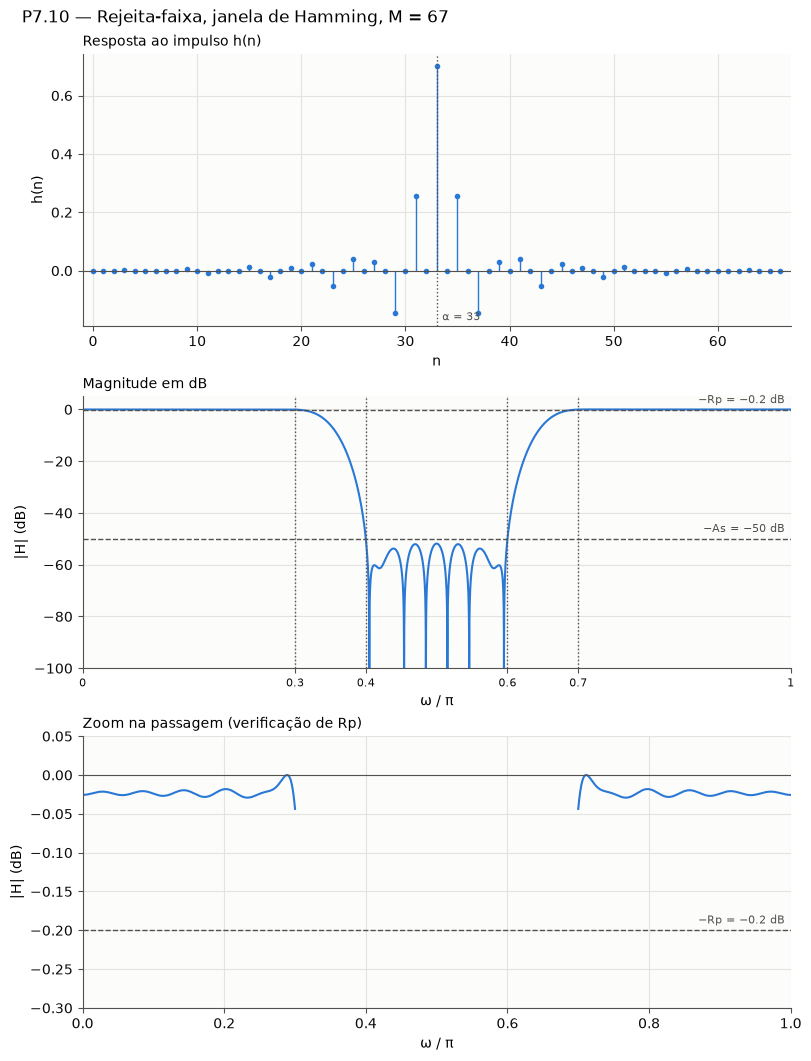

In [3]:
fig = p7_10.plot(d)
plt.show()

## 3. Validação contra a especificação

In [4]:
print(p7_10.validate(d))

Validação P7.10 (Tipo 1 de fase linear)
  [OK  ] Rp [dB] (grade livro): 0.0435 <= 0.2000  (folga +0.1565)
  [OK  ] As [dB] (grade livro): 50.0439 >= 50.0000  (folga +0.0439)
  [OK  ] Rp [dB] (grade densa): 0.0436 <= 0.2000  (folga +0.1564)
  [OK  ] As [dB] (grade densa): 50.0440 >= 50.0000  (folga +0.0440)
  Resultado: ATENDE à especificação


### 3.1 Por que a margem em $A_s$ é tão estreita (≈ 0.04 dB)?

A Tabela 7.1 atribui ≈ 53 dB à Hamming, mas o filtro medido dá 50.04 dB. O zoom na rejeição mostra a causa: o pior ponto **não é um lóbulo lateral**. Os lóbulos ficam em torno de −52 dB. O pior ponto é a própria borda $\omega_s = 0.4\pi$ (e, por simetria, $0.6\pi$), onde a transição ainda não terminou.

Ou seja, a largura $6.6\pi/M$ da tabela é aproximada: com $M = 67$, a resposta só atinge o nível dos lóbulos um pouco depois da borda. O mesmo ocorre num passa-baixas Hamming com $M = 67$ e a mesma transição (≈ 50.1 dB), então o efeito não vem de haver duas transições.

Pior ponto da rejeição: ω = 0.4000π, |H| = -50.0440 dB


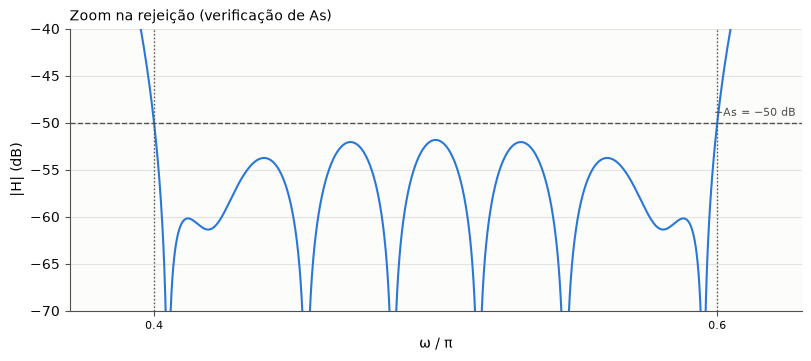

In [5]:
w = analysis.frequency_grid(SPEC.edges, 200001)
db = analysis.magnitude_db(analysis.frequency_response(d.h, w))
stop = (w >= 0.4 * np.pi - 1e-12) & (w <= 0.6 * np.pi + 1e-12)
i = np.argmax(db[stop])
print(f"Pior ponto da rejeição: ω = {w[stop][i] / np.pi:.4f}π, |H| = {db[stop][i]:.4f} dB")

fig, ax = plt.subplots(figsize=(8, 3.5), constrained_layout=True)
plotting.plot_magnitude_db(ax, w, db, SPEC.edges, as_db=SPEC.as_db, ylim=(-70, -40),
                           title="Zoom na rejeição (verificação de As)")
ax.set_xlim(0.37, 0.63)
plt.show()

### 3.2 O comprimento da tabela também é o mínimo?

O enunciado não pede comprimento mínimo, mas vale conferir. Varrendo os comprimentos ímpares vizinhos (só ímpares, pelo argumento de paridade):

In [6]:
wg = analysis.frequency_grid(SPEC.edges, analysis.DENSE_GRID_POINTS)
print(" M     Rp [dB]   As [dB]   atende?")
for M in (61, 63, 65, 67, 69):
    dm = design_fixed_window(SPEC, "hamming", M=M)
    rp, as_ = analysis.measure_rp_as(dm.h, SPEC.passbands, SPEC.stopbands, wg)
    print(f"{M:3d}   {rp:7.4f}   {as_:7.2f}   {'sim' if rp <= SPEC.rp_db and as_ >= SPEC.as_db else 'não'}")

 M     Rp [dB]   As [dB]   atende?
 61    0.1165     39.25   não
 63    0.0800     42.82   não
 65    0.0674     44.95   não
 67    0.0436     50.04   sim
 69    0.0288     54.63   sim


$M = 65$ dá só ≈ 44.9 dB. Portanto $M = 67$, da Tabela 7.1, é também o menor comprimento ímpar que atende ao enunciado com a janela de Hamming.

### 3.3 Verificação independente e comparação com o DTA

In [7]:
from scipy.signal import firwin
ref = firwin(d.M, list(d.cutoffs), window="hamming", pass_zero=True, scale=False)
print("max |h − h_firwin| =", np.max(np.abs(d.h - ref)))

_, as_2049 = analysis.measure_rp_as(d.h, SPEC.passbands, SPEC.stopbands, np.linspace(0, np.pi, 2049))
print(f"A_s numa grade de 2049 pontos (sem as bordas): {as_2049:.2f} dB")

max |h − h_firwin| = 1.1851323752131417e-16
A_s numa grade de 2049 pontos (sem as bordas): 51.14 dB


O DTA informa $A_s = 51.11$ dB e $R_p = 0.0417$ dB. Esses valores se reproduzem numa grade de 2049 pontos, que **não contém** as bordas 0.4π e 0.6π. Como o pior ponto é justamente a borda, essa grade superestima $A_s$ em ≈ 1 dB. O valor correto, com as bordas na grade, é **50.04 dB** (decisão D8 do plano).

## 4. Conclusão

- Com a janela de Hamming e $M = 67$ (Tipo 1, $\alpha = 33$), o filtro atende à especificação: $R_p \approx 0.044$ dB $\le 0.2$ dB e $A_s \approx 50.04$ dB $\ge 50$ dB.
- A folga em $A_s$ é de só 0.04 dB. O pior ponto é a borda da rejeição, não um lóbulo lateral: o valor nominal de 53 dB da Tabela 7.1 só é atingido um pouco depois da borda.
- $M = 67$ é o menor comprimento ímpar que atende. Com $M = 65$, $A_s$ cai para ≈ 44.9 dB.
- O $A_s = 51.11$ dB do DTA vem de uma grade sem as bordas e não deve ser usado como referência.